# Exploratory data analysis

Three gold-labelled sources, never pooled: **SemEval-2023 Task 3, subtask 3** in Polish and English (paragraphs, 23 persuasion techniques) and **MIPD** (Polish articles, 11 manipulation techniques).

The notebook reads the prepared files in `data/` through `routing.data`, so it sees exactly what the experiments see. It writes the figures used in the report to `latex/img/` and the tables to `outputs/eda/`.

Run it from the repository root with the `nlp-routing` environment:

```bash
jupyter nbconvert --to notebook --execute --inplace notebooks/01_eda.ipynb
```

Contents: 1. sizes and splits, 2. labels per technique and split, 3. label sets, 4. text length, 5. duplicates and leakage, 6. MIPD credibility, 7. co-occurrence of techniques, 8. what follows for the experiments.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from routing.data import REPO_ROOT, load_items, load_split
from routing.labels import SOURCES, labels_for
from routing.splits import normalise

IMG = REPO_ROOT / "latex" / "img"
OUT = REPO_ROOT / "outputs" / "eda"
OUT.mkdir(parents=True, exist_ok=True)

NAMES = {"semeval_pl": "SemEval PL", "semeval_en": "SemEval EN", "mipd": "MIPD"}
COLOR = {"semeval_pl": "#2a78d6", "semeval_en": "#eb6834", "mipd": "#1baf7a"}  # fixed colour per source
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3de"
plt.rcParams.update({
    "font.size": 8, "axes.titlesize": 9, "axes.labelsize": 8, "axes.edgecolor": MUTED, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "figure.dpi": 110, "savefig.bbox": "tight", "legend.frameon": False,
})
pd.set_option("display.max_rows", 60, "display.width", 200)

data = {}
for source in SOURCES:
    items = load_items(source).merge(load_split(source)[["item_id", "role"]], on="item_id")
    items["n_words"] = items["text"].str.split().str.len()
    items["n_labels"] = items[list(labels_for(source))].sum(axis=1)
    data[source] = items
{name: len(frame) for name, frame in data.items()}

{'semeval_pl': 3110, 'semeval_en': 12625, 'mipd': 15356}

## 1. Sizes and splits

The official splits are the boundaries of the study. SemEval test labels are not public, so `dev` is the test set and `train` supplies everything else; MIPD has official train, validation and test splits.

In [2]:
rows = []
for source, items in data.items():
    labels = list(labels_for(source))
    for split, part in items.groupby("original_set", sort=False):
        rows.append({
            "source": NAMES[source], "official split": split, "articles": part["article_id"].nunique(),
            "items": len(part), "median words": int(part["n_words"].median()),
            "items without a technique": f"{(part['n_labels'] == 0).mean():.1%}",
            "mean techniques per item": round(part["n_labels"].mean(), 2),
            "techniques present": f"{int((part[labels].sum() > 0).sum())}/{len(labels)}",
        })
sizes = pd.DataFrame(rows).set_index(["source", "official split"])
sizes.to_csv(OUT / "sizes.csv")
sizes

articles  items  median words items without a technique  mean techniques per item techniques present
source     official split                                                                                                      
SemEval PL train                145   2310            39                     46.7%                      0.95              23/23
           dev                   49    800            38                     47.1%                      0.98              23/23
SemEval EN train                446   9498            33                     60.4%                      0.62              19/23
           dev                   90   3127            19                     64.2%                      0.53              19/23
MIPD       test                1521   1521           526                     75.5%                      0.56              11/11
           train              10749  10749           544                     75.8%                      0.55              11/11
           validation          3086   3086           554                     76.5%                      0.53              11/11

Roles inside the official splits (`python -m routing.splits`, whole articles, seed 0). The pilot subset and the calibration set come from training data (MIPD: calibration from the validation split); the test role is the whole Polish dev split, 1,500 paragraphs of the English dev split and the whole MIPD test split. For MIPD the pilot subset and the calibration set hold disinformative articles only, and `credible_check` is a sample of credible validation articles (see section 6).

In [3]:
order = ["fewshot", "pilot", "calibration", "credible_check", "test", "unused", "dropped_duplicate"]
roles = pd.concat({
    NAMES[s]: pd.crosstab(d["original_set"], d["role"]).reindex(columns=order, fill_value=0) for s, d in data.items()
})
articles = pd.concat({
    NAMES[s]: d.groupby("role")["article_id"].nunique().reindex(order, fill_value=0) for s, d in data.items()
}, axis=1).T
display(roles)
print("articles per role")
display(articles)
assigned = {s: d[~d["role"].isin(["unused", "dropped_duplicate"])] for s, d in data.items()}
shared = {NAMES[s]: int(d.groupby("article_id")["role"].nunique().gt(1).sum()) for s, d in assigned.items()}
print("articles that appear in more than one role:", shared)

role                     fewshot  pilot  calibration  credible_check  test  unused  dropped_duplicate
           original_set                                                                              
SemEval PL dev                 0      0            0               0   800       0                  0
           train             153    219         1002               0     0     935                  1
SemEval EN dev                 0      0            0               0  1500    1627                  0
           train             170    208         1003               0     0    8117                  0
MIPD       test                0      0            0               0  1521       0                  0
           train             200    100            0               0     0   10449                  0
           validation          0      0          600             200     0    2286                  0

articles per role


role,fewshot,pilot,calibration,credible_check,test,unused,dropped_duplicate
SemEval PL,10,11,66,0,49,58,1
SemEval EN,10,9,44,0,44,429,0
MIPD,200,100,600,200,1521,12735,0


articles that appear in more than one role: {'SemEval PL': 0, 'SemEval EN': 0, 'MIPD': 0}


## 2. Labels per technique and split

Counts of gold positives for every technique in every official split, and in the items that form the test role (for English a part of the dev split). A technique is reported on its own only if it has **at least 30 gold positives in the test role**; the others are reported together as "rare techniques".

In [4]:
MIN_SUPPORT = 30
counts = {}
for source, items in data.items():
    labels = list(labels_for(source))
    scope = items[items["disinformative"] == 1] if source == "mipd" else items  # see section 6
    table = scope.groupby("original_set", sort=False)[labels].sum().T
    table["all"] = table.sum(axis=1)
    table["test role"] = scope.loc[scope["role"] == "test", labels].sum()
    table["own row in results"] = np.where(table["test role"] >= MIN_SUPPORT, "yes", "no")
    table = table.sort_values("all", ascending=False)
    table.to_csv(OUT / f"label_counts_{source}.csv")
    counts[source] = table
    print(f"{NAMES[source]}: {int((table['test role'] >= MIN_SUPPORT).sum())} of {len(labels)} techniques reach "
          f"{MIN_SUPPORT} gold positives in the test role; {int((table['all'] == 0).sum())} never occur")
    display(table)

SemEval PL: 11 of 23 techniques reach 30 gold positives in the test role; 0 never occur


original_set,train,dev,all,test role,own row in results
Name_Calling-Labeling,475,111,586,111,yes
Loaded_Language,310,93,403,93,yes
Doubt,295,96,391,96,yes
Appeal_to_Hypocrisy,162,76,238,76,yes
Questioning_the_Reputation,164,57,221,57,yes
Exaggeration-Minimisation,111,40,151,40,yes
Appeal_to_Values,101,50,151,50,yes
Appeal_to_Fear-Prejudice,108,36,144,36,yes
Guilt_by_Association,94,30,124,30,yes
Flag_Waving,68,28,96,28,no


SemEval EN: 8 of 23 techniques reach 30 gold positives in the test role; 4 never occur


original_set,train,dev,all,test role,own row in results
Loaded_Language,1809,483,2292,184,yes
Name_Calling-Labeling,979,250,1229,92,yes
Doubt,518,187,705,86,yes
Repetition,544,141,685,60,yes
Exaggeration-Minimisation,466,115,581,39,yes
Appeal_to_Fear-Prejudice,310,137,447,61,yes
Flag_Waving,287,96,383,32,yes
Causal_Oversimplification,213,24,237,7,no
False_Dilemma-No_Choice,122,63,185,31,yes
Appeal_to_Authority,154,28,182,14,no


MIPD: 8 of 11 techniques reach 30 gold positives in the test role; 0 never occur


original_set,train,validation,test,all,test role,own row in results
EXAGGERATION,1514,405,234,2153,234,yes
CHERRY_PICKING,1082,295,149,1526,149,yes
REFERENCE_ERROR,762,227,119,1108,119,yes
FALSE_CAUSE,627,193,95,915,95,yes
EMOTIONAL_CONTENT,635,182,92,909,92,yes
ANECDOTE,310,88,44,442,44,yes
STRAWMAN,321,76,37,434,37,yes
WHATABOUTISM,307,82,37,426,37,yes
MISLEADING_CLICKBAIT,123,41,13,177,13,no
LEADING_QUESTIONS,92,20,15,127,15,no


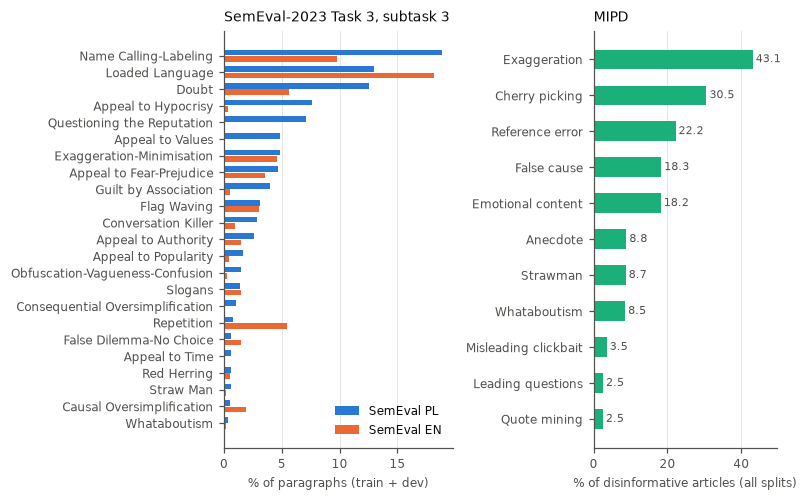

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 4.6), gridspec_kw={"width_ratios": [1.25, 1]})

# SemEval: share of paragraphs per technique, Polish against English, ordered by the Polish share.
labels = list(labels_for("semeval_pl"))
share = pd.DataFrame({s: data[s][labels].mean() * 100 for s in ("semeval_pl", "semeval_en")})
share = share.sort_values("semeval_pl")
y = np.arange(len(share))
ax = axes[0]
for offset, source in ((0.19, "semeval_pl"), (-0.19, "semeval_en")):
    ax.barh(y + offset, share[source], height=0.34, color=COLOR[source], label=NAMES[source], linewidth=0)
ax.set_yticks(y, [l.replace("_", " ") for l in share.index])
ax.set_xlabel("% of paragraphs (train + dev)")
ax.set_title("SemEval-2023 Task 3, subtask 3", loc="left")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")

# MIPD: share of disinformative articles per technique.
labels = list(labels_for("mipd"))
disinformative = data["mipd"][data["mipd"]["disinformative"] == 1]
share_mipd = (disinformative[labels].mean() * 100).sort_values()
ax = axes[1]
bars = ax.barh(np.arange(len(share_mipd)), share_mipd, height=0.55, color=COLOR["mipd"], linewidth=0)
ax.bar_label(bars, fmt="%.1f", padding=2, color=MUTED, fontsize=7)
ax.set_yticks(np.arange(len(share_mipd)), [l.replace("_", " ").capitalize() for l in share_mipd.index])
ax.set_xlabel("% of disinformative articles (all splits)")
ax.set_title("MIPD", loc="left")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, share_mipd.max() * 1.15)

fig.tight_layout()
fig.savefig(IMG / "eda_label_frequency.pdf")
plt.show()

## 3. Label sets

The study scores a prediction as correct only if the **whole label set** is right, so the size and variety of the gold label sets matter: an item without any technique is right as soon as the model predicts nothing.

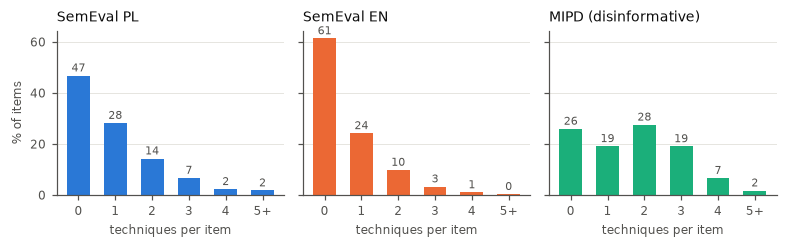

,items,distinct label sets,share of the most frequent set,share of the 10 most frequent sets,items with 2 or more techniques,max techniques
source,,,,,,
SemEval PL,3110,379,46.8%,69.9%,25.0%,7
SemEval EN,12625,368,61.3%,84.4%,14.5%,9
MIPD,4997,311,25.9%,55.7%,55.0%,7


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.3), sharey=True)
rows = []
for ax, (source, items) in zip(axes, data.items()):
    scope = items[items["disinformative"] == 1] if source == "mipd" else items
    size = scope["n_labels"].clip(upper=5)
    share = size.value_counts(normalize=True).reindex(range(6), fill_value=0) * 100
    bars = ax.bar(share.index, share, width=0.62, color=COLOR[source], linewidth=0)
    ax.bar_label(bars, fmt="%.0f", padding=1, color=MUTED, fontsize=7)
    ax.set_xticks(range(6), ["0", "1", "2", "3", "4", "5+"])
    ax.set_title(NAMES[source] + (" (disinformative)" if source == "mipd" else ""), loc="left")
    ax.set_xlabel("techniques per item")
    ax.grid(axis="x", visible=False)
    sets = scope[list(labels_for(source))].astype(str).agg("".join, axis=1)
    top = sets.value_counts(normalize=True)
    rows.append({"source": NAMES[source], "items": len(scope), "distinct label sets": sets.nunique(),
                 "share of the most frequent set": f"{top.iloc[0]:.1%}",
                 "share of the 10 most frequent sets": f"{top.iloc[:10].sum():.1%}",
                 "items with 2 or more techniques": f"{(scope['n_labels'] >= 2).mean():.1%}",
                 "max techniques": int(scope["n_labels"].max())})
axes[0].set_ylabel("% of items")
fig.tight_layout()
fig.savefig(IMG / "eda_label_set_size.pdf")
plt.show()
pd.DataFrame(rows).set_index("source")

## 4. Text length

SemEval items are paragraphs, MIPD items are whole articles. MIPD articles are cut after 2,000 words before they are sent to a model (`routing.data.MIPD_MAX_WORDS`); the lengths below are measured before the cut, on the original text.

,SemEval PL,SemEval EN,MIPD
min,1,1,19
5%,3,4,183
25%,17,14,347
median,39,28,544
75%,63,47,907
95%,114,101,1924
99%,191,176,4061
max,615,1031,25018


MIPD articles longer than 2000 words: 711 (4.6%); flagged as truncated in the item table: 711
SemEval paragraphs of at most 3 words: {'SemEval PL': 172, 'SemEval EN': 626}


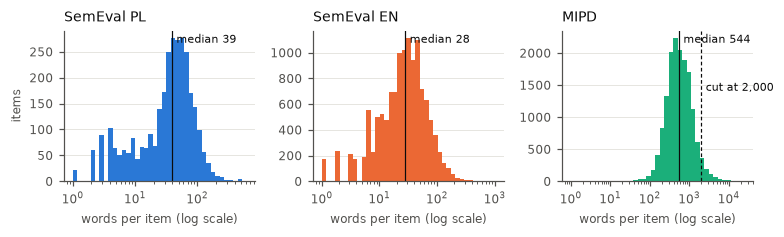

paragraphs per article


,SemEval PL,SemEval EN
count,194.0,536.0
mean,16.0,23.6
min,3.0,3.0
50%,12.0,19.0
max,79.0,124.0


In [7]:
from routing.data import DATA_DIR, MIPD_MAX_WORDS

full = pd.read_csv(DATA_DIR / "mipd" / "articles.csv", dtype={"article_id": str}, keep_default_na=False)
words = {s: d["n_words"] for s, d in data.items()}
words["mipd"] = full["full_article"].str.split().str.len()  # before the cut

quantiles = pd.DataFrame({NAMES[s]: w.quantile([0, .05, .25, .5, .75, .95, .99, 1]).round().astype(int) for s, w in words.items()})
quantiles.index = ["min", "5%", "25%", "median", "75%", "95%", "99%", "max"]
display(quantiles)
print(f"MIPD articles longer than {MIPD_MAX_WORDS} words: {(words['mipd'] > MIPD_MAX_WORDS).sum()} "
      f"({(words['mipd'] > MIPD_MAX_WORDS).mean():.1%}); flagged as truncated in the item table: {int(data['mipd']['truncated'].sum())}")
print("SemEval paragraphs of at most 3 words:", {NAMES[s]: int((words[s] <= 3).sum()) for s in ("semeval_pl", "semeval_en")})

fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.2))
for ax, source in zip(axes, data):
    w = words[source].clip(lower=1)
    bins = np.logspace(0, np.log10(w.max()), 40)
    ax.hist(w, bins=bins, color=COLOR[source], linewidth=0)
    ax.set_xscale("log")
    ax.set_title(NAMES[source], loc="left")
    ax.set_xlabel("words per item (log scale)")
    ax.grid(axis="x", visible=False)
    ax.axvline(w.median(), color=INK, linewidth=0.8)
    ax.annotate(f"median {int(w.median())}", (w.median(), ax.get_ylim()[1]), xytext=(3, -8), textcoords="offset points", fontsize=7)
axes[2].axvline(MIPD_MAX_WORDS, color=INK, linewidth=0.8, linestyle=(0, (3, 2)))
axes[2].annotate("cut at 2,000", (MIPD_MAX_WORDS, axes[2].get_ylim()[1] * 0.6), xytext=(3, 0), textcoords="offset points", fontsize=7)
axes[0].set_ylabel("items")
fig.tight_layout()
fig.savefig(IMG / "eda_text_length.pdf")
plt.show()

per_article = pd.DataFrame({NAMES[s]: data[s].groupby("article_id").size().describe().round(1) for s in ("semeval_pl", "semeval_en")})
print("paragraphs per article")
per_article.loc[["count", "mean", "min", "50%", "max"]]

Does length relate to the labels? If longer items carry more techniques, text length alone can predict whether an *empty* prediction is right, which is why text length is one of the negative controls.

In [8]:
rows = []
for source, items in data.items():
    scope = items[items["disinformative"] == 1] if source == "mipd" else items
    rows.append({
        "source": NAMES[source],
        "Spearman: words vs number of techniques": round(scope["n_words"].corr(scope["n_labels"], method="spearman"), 3),
        "median words, no technique": int(scope.loc[scope["n_labels"] == 0, "n_words"].median()),
        "median words, 1+ technique": int(scope.loc[scope["n_labels"] > 0, "n_words"].median()),
    })
pd.DataFrame(rows).set_index("source")

,Spearman: words vs number of techniques,"median words, no technique","median words, 1+ technique"
source,,,
SemEval PL,0.451,27,50
SemEval EN,0.352,22,38
MIPD,0.030,725,504


## 5. Duplicates and leakage

Texts are compared after normalising whitespace and case. A text that occurs more than once can carry different gold labels, and a text that occurs in both training and evaluation data would leak.

In [9]:
rows = []
for source, items in data.items():
    labels = list(labels_for(source))
    key = items["text"].map(normalise)
    groups = items.assign(key=key, gold=items[labels].astype(str).agg("".join, axis=1)).groupby("key")
    repeated = groups.filter(lambda g: len(g) > 1)
    conflicting = repeated.groupby("key")["gold"].nunique().gt(1).sum()
    sets_per_text = groups["original_set"].nunique()
    evaluation = set(key[items["role"] == "test"])
    development = key[items["role"].isin(["fewshot", "pilot", "calibration", "credible_check"])]
    rows.append({
        "source": NAMES[source],
        "items sharing a text with another item": len(repeated),
        "distinct repeated texts": repeated["key"].nunique(),
        "repeated texts with conflicting gold": int(conflicting),
        "texts in more than one official split": int(sets_per_text.gt(1).sum()),
        "development items whose text is in the test role": int(development.isin(evaluation).sum()),
    })
pd.DataFrame(rows).set_index("source").T

source,SemEval PL,SemEval EN,MIPD
items sharing a text with another item,17,1088,0
distinct repeated texts,6,234,0
repeated texts with conflicting gold,0,30,0
texts in more than one official split,2,34,0
development items whose text is in the test role,0,0,0


In [10]:
# What the repeated English texts are: mostly very short paragraphs such as headings and bylines.
en = data["semeval_en"]
key = en["text"].map(normalise)
repeated = en[key.duplicated(keep=False)]
print("median words of repeated English paragraphs:", int(repeated["n_words"].median()), "| of all:", int(en["n_words"].median()))
print("share of repeated English paragraphs without a technique:", f"{(repeated['n_labels'] == 0).mean():.1%}")
key[key.duplicated(keep=False)].value_counts().head(8).rename("occurrences").to_frame()

median words of repeated English paragraphs: 10 | of all: 28
share of repeated English paragraphs without a technique: 92.7%


,occurrences
text,
email *,111
take our poll - story continues below,88
who should replace nikki haley as our ambassador to the u.n.? * john bolton richard grenell dina powell heather nauert ivanka trump,30
email this field is for validation purposes and should be left unchanged. completing this poll grants you access to freedom outpost updates free of charge. you may opt out at anytime. you also agree to this site's privacy policy and terms of use.,25
whom do you consider to be the most corrupt democrat politician? * dianne feinstein maxine waters adam schiff chuck schumer kamala harris kirsten gillibrand keith ellison cory booker,25
"will brett kavanaugh be confirmed to the supreme court? * yes, he will be confirmed. no, he will not be confirmed.",23
who should replace nikki haley as our ambassador to the u.n.? who should replace nikki haley as our ambassador to the u.n.?,23
comments this field is for validation purposes and should be left unchanged. completing this poll grants you access to freedom outpost updates free of charge. you may opt out at anytime. you also agree to this site's privacy policy and terms of use.,22


## 6. MIPD: credibility and techniques

MIPD labels every article as credible or disinformative. Manipulation techniques were annotated **only for disinformative articles**, so a credible article has no technique by construction, not because an annotator looked for techniques and found none. The two kinds of "empty" must not be mixed.

In [11]:
mipd = data["mipd"]
kind = np.select(
    [mipd["disinformative"] == 0, mipd["n_labels"] == 0], ["credible", "disinformative, no technique"],
    "disinformative, 1+ technique")
table = pd.crosstab(mipd["original_set"], kind, margins=True, margins_name="all")
table = table.reindex(["train", "validation", "test", "all"])
display(table)
print("credible articles with a technique label:", int(((mipd["disinformative"] == 0) & (mipd["n_labels"] > 0)).sum()))
print("share of all 'empty' articles that are credible:", f"{(kind[mipd['n_labels'] == 0] == 'credible').mean():.1%}")

by_role = pd.crosstab(mipd["role"], kind).reindex(["fewshot", "pilot", "calibration", "credible_check", "test"]).fillna(0).astype(int)
print("the same by role")
display(by_role)

category = pd.crosstab(mipd["category"], mipd["disinformative"].map({0: "credible", 1: "disinformative"}))
category["share disinformative"] = (category["disinformative"] / category.sum(axis=1)).round(3)
print("thematic categories")
category.sort_values("disinformative", ascending=False).head(12)

col_0,credible,"disinformative, 1+ technique","disinformative, no technique",all
original_set,,,,
train,7247,2603,899,10749
validation,2081,726,279,3086
test,1031,373,117,1521
all,10359,3702,1295,15356


credible articles with a technique label: 0
share of all 'empty' articles that are credible: 88.9%
the same by role


col_0,credible,"disinformative, 1+ technique","disinformative, no technique"
role,,,
fewshot,141,44,15
pilot,0,72,28
calibration,0,438,162
credible_check,200,0,0
test,1031,373,117


thematic categories


disinformative,credible,disinformative,share disinformative
category,,,
COVID,4760,1289,0.213
WOMENS_RIGHTS,498,566,0.532
LGBT,572,464,0.448
NEWS_OR_OTHER,618,415,0.402
PSEUDOMEDICINE,608,405,0.400
ASTRONOMY_AND_AERONAUTICS,647,399,0.381
CLIMATE_CRISIS,634,377,0.373
THE_WAR_IN_UKRAINE,650,376,0.366
MIGRATIONS,665,365,0.354


## 7. Co-occurrence of techniques

How often technique B is present when technique A is. Strong pairs mean that decisions for different techniques are not independent, which matters for the item-level confidence scores that combine per-technique values.

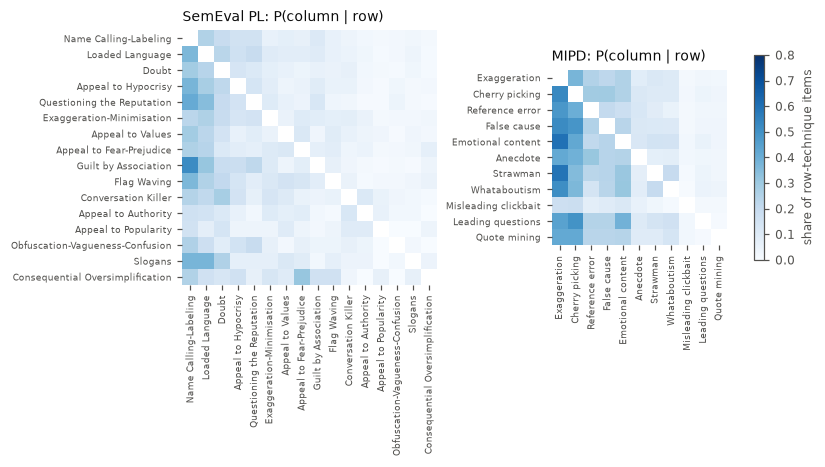

SemEval PL strongest pairs: Guilt_by_Association -> Name_Calling-Labeling 52%; Questioning_the_Reputation -> Name_Calling-Labeling 41%; Appeal_to_Hypocrisy -> Name_Calling-Labeling 37%; Slogans -> Loaded_Language 37%; Slogans -> Name_Calling-Labeling 37%
SemEval EN strongest pairs: Exaggeration-Minimisation -> Loaded_Language 48%; Appeal_to_Hypocrisy -> Loaded_Language 42%; Name_Calling-Labeling -> Loaded_Language 41%; Causal_Oversimplification -> Loaded_Language 41%; Repetition -> Loaded_Language 33%
MIPD strongest pairs: EMOTIONAL_CONTENT -> EXAGGERATION 60%; STRAWMAN -> EXAGGERATION 59%; CHERRY_PICKING -> EXAGGERATION 53%; FALSE_CAUSE -> EXAGGERATION 52%; WHATABOUTISM -> EXAGGERATION 51%


In [12]:
def conditional(frame, labels):
    x = frame[labels].to_numpy(dtype=float)
    together = x.T @ x
    return pd.DataFrame(together / np.maximum(np.diag(together)[:, None], 1), index=labels, columns=labels)

fig, axes = plt.subplots(1, 2, figsize=(7.4, 4.4), gridspec_kw={"width_ratios": [1.45, 1]}, layout="constrained")
for ax, source in zip(axes, ("semeval_pl", "mipd")):
    labels = list(labels_for(source))
    scope = data[source] if source != "mipd" else data[source][data[source]["disinformative"] == 1]
    freq = scope[labels].sum().sort_values(ascending=False)
    labels = [l for l in freq.index if freq[l] >= 30]
    matrix = conditional(scope, labels).to_numpy().copy()
    np.fill_diagonal(matrix, np.nan)
    image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=0.8)
    short = [l.replace("_", " ").capitalize() if source == "mipd" else l.replace("_", " ") for l in labels]
    ax.set_xticks(range(len(labels)), short, rotation=90, fontsize=6)
    ax.set_yticks(range(len(labels)), short, fontsize=6)
    ax.set_title(f"{NAMES[source]}: P(column | row)", loc="left")
    ax.grid(False)
    for side in ax.spines.values():
        side.set_visible(False)
fig.colorbar(image, ax=axes, shrink=0.6, label="share of row-technique items")
fig.savefig(IMG / "eda_cooccurrence.pdf")
plt.show()

for source in ("semeval_pl", "semeval_en", "mipd"):
    labels = list(labels_for(source))
    scope = data[source] if source != "mipd" else data[source][data[source]["disinformative"] == 1]
    matrix = conditional(scope, labels)
    support = scope[labels].sum()
    pairs = [(a, b, matrix.at[a, b]) for a in labels for b in labels if a != b and support[a] >= 30]
    top = sorted(pairs, key=lambda p: -p[2])[:5]
    print(NAMES[source], "strongest pairs:", "; ".join(f"{a} -> {b} {v:.0%}" for a, b, v in top))

## 8. Floors for the evaluation

Two numbers that any model result has to be read against, per role: the exact-set accuracy of predicting **no technique for every item**, and the share of items without a technique. For MIPD they are computed on disinformative articles.

In [13]:
rows = []
for source, items in data.items():
    scope = items[items["disinformative"] == 1] if source == "mipd" else items
    for role in ("pilot", "calibration", "test"):
        part = scope[scope["role"] == role]
        labels = list(labels_for(source))
        rows.append({"source": NAMES[source], "role": role, "items": len(part), "articles": part["article_id"].nunique(),
                     "exact-set accuracy of 'no technique'": round((part["n_labels"] == 0).mean(), 3),
                     "techniques with 30+ positives": int((part[labels].sum() >= 30).sum()),
                     "gold positives": int(part[labels].to_numpy().sum())})
floors = pd.DataFrame(rows).set_index(["source", "role"])
floors.to_csv(OUT / "floors.csv")
floors

items  articles  exact-set accuracy of 'no technique'  techniques with 30+ positives  gold positives
source     role                                                                                                             
SemEval PL pilot          219        11                                 0.457                              1             192
           calibration   1002        66                                 0.445                             10            1058
           test           800        49                                 0.471                             11             786
SemEval EN pilot          208         9                                 0.683                              0              89
           calibration   1003        44                                 0.617                              6             593
           test          1500        44                                 0.681                              8             666
MIPD       pilot          100       100                                 0.280                              1             158
           calibration    600       600                                 0.270                              8             993
           test           490       490                                 0.239                              8             849